In [1]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from urllib.request import urlretrieve
from ultralytics import YOLO

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
print("PyTorch Version:", torch.__version__)

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

PyTorch Version: 2.14.0+cpu
CUDA Available: False
Using CPU


In [11]:
import os

print("Current directory:", os.getcwd())
print("Folders:", os.listdir())

Current directory: d:\ObjectDetection\notebooks
Folders: ['day1.ipynb']


In [12]:
project_dir = Path("..")

image_dir = project_dir / "sample_images"

image_dir.mkdir(parents=True, exist_ok=True)

print("Project directory created!")

Project directory created!


In [13]:
image_url = "https://ultralytics.com/images/bus.jpg"

image_path = image_dir / "bus.jpg"

urlretrieve(image_url, image_path)

print("Image downloaded successfully!")
print("Image path:", image_path)

Image downloaded successfully!
Image path: ..\sample_images\bus.jpg


In [14]:
image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError("Image not found!")

print("Image shape:", image.shape)
print("Image dimensions:", image.shape[:2])

Image shape: (1080, 810, 3)
Image dimensions: (1080, 810)


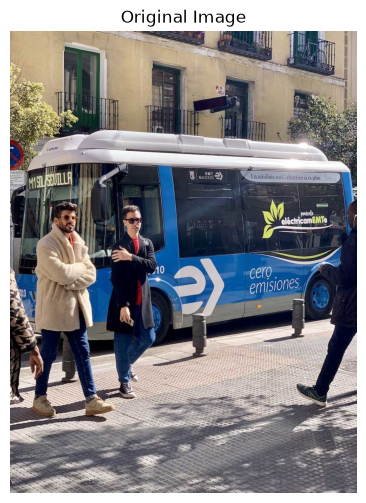

In [15]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))

plt.imshow(image_rgb)

plt.title("Original Image")
plt.axis("off")

plt.show()

In [16]:
model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


In [17]:
results = model.predict(
    source=str(image_path),
    conf=0.25,
    save=True,
    verbose=True
)

print("Object detection completed!")


image 1/1 d:\ObjectDetection\notebooks\..\sample_images\bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 175.2ms
Speed: 13.3ms preprocess, 175.2ms inference, 23.9ms postprocess per image at shape (1, 3, 640, 480)
Results saved to D:\ObjectDetection\notebooks\runs\detect\predict
Object detection completed!


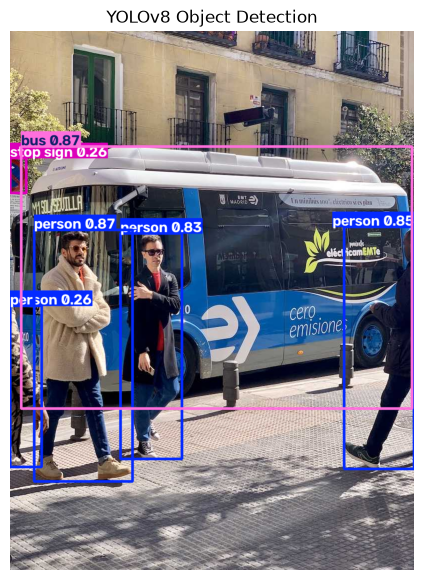

In [18]:
result = results[0]

detected_image = result.plot()

detected_image_rgb = cv2.cvtColor(
    detected_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))

plt.imshow(detected_image_rgb)

plt.title("YOLOv8 Object Detection")
plt.axis("off")

plt.show()

In [19]:
result = results[0]

boxes = result.boxes.xyxy

confidences = result.boxes.conf

class_ids = result.boxes.cls

print("Detected Objects:\n")

for box, confidence, class_id in zip(
    boxes, confidences, class_ids
):

    class_name = model.names[int(class_id)]

    print(
        f"Object: {class_name} | "
        f"Confidence: {confidence.item():.2f} | "
        f"Bounding Box: {box.tolist()}"
    )

Detected Objects:

Object: bus | Confidence: 0.87 | Bounding Box: [22.87126922607422, 231.27731323242188, 805.002685546875, 756.8404541015625]
Object: person | Confidence: 0.87 | Bounding Box: [48.55046463012695, 398.5522155761719, 245.34559631347656, 902.7026977539062]
Object: person | Confidence: 0.85 | Bounding Box: [669.472900390625, 392.1860656738281, 809.7201538085938, 877.0354614257812]
Object: person | Confidence: 0.83 | Bounding Box: [221.5172882080078, 405.7985534667969, 344.9706115722656, 857.53662109375]
Object: person | Confidence: 0.26 | Bounding Box: [0.0, 550.5250244140625, 63.006980895996094, 873.4429321289062]
Object: stop sign | Confidence: 0.26 | Bounding Box: [0.05817389488220215, 254.4593963623047, 32.557411193847656, 324.8741455078125]


In [20]:
from collections import Counter

detected_classes = [
    model.names[int(class_id)]
    for class_id in result.boxes.cls
]

object_counts = Counter(detected_classes)

print("Object Counts:")

for object_name, count in object_counts.items():
    print(f"{object_name}: {count}")

Object Counts:
bus: 1
person: 4
stop sign: 1


In [21]:
thresholds = [0.25, 0.50, 0.75]

for threshold in thresholds:

    prediction = model.predict(
        source=str(image_path),
        conf=threshold,
        verbose=False
    )[0]

    print(
        f"Threshold: {threshold} | "
        f"Objects detected: {len(prediction.boxes)}"
    )

Threshold: 0.25 | Objects detected: 6
Threshold: 0.5 | Objects detected: 4
Threshold: 0.75 | Objects detected: 4


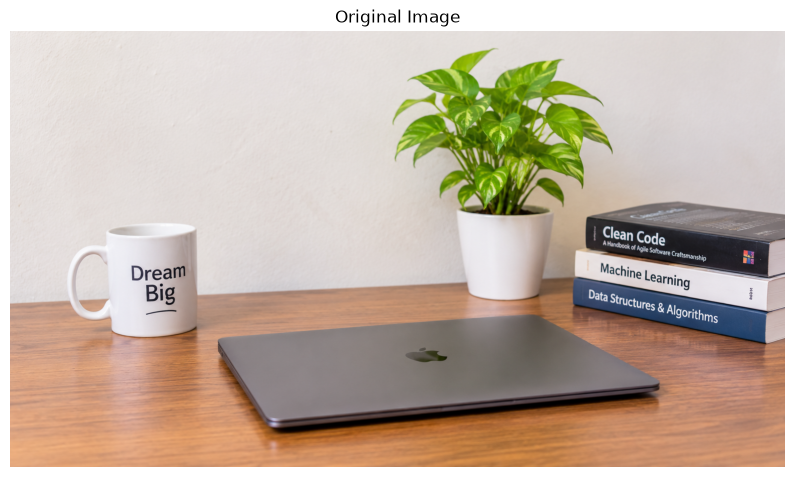

In [23]:
image_path1 = image_dir / "dream.jpg"
image = cv2.imread(str(image_path1))

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))

plt.imshow(image_rgb)

plt.title("Original Image")
plt.axis("off")

plt.show()

In [24]:
results = model.predict(
    source=str(image_path1),
    conf=0.25,
    save=True,
    verbose=True
)

print("Object detection completed!")


image 1/1 d:\ObjectDetection\notebooks\..\sample_images\dream.jpg: 384x640 2 cups, 1 potted plant, 1 laptop, 2 books, 142.7ms
Speed: 38.0ms preprocess, 142.7ms inference, 2.0ms postprocess per image at shape (1, 3, 384, 640)
Results saved to D:\ObjectDetection\notebooks\runs\detect\predict
Object detection completed!


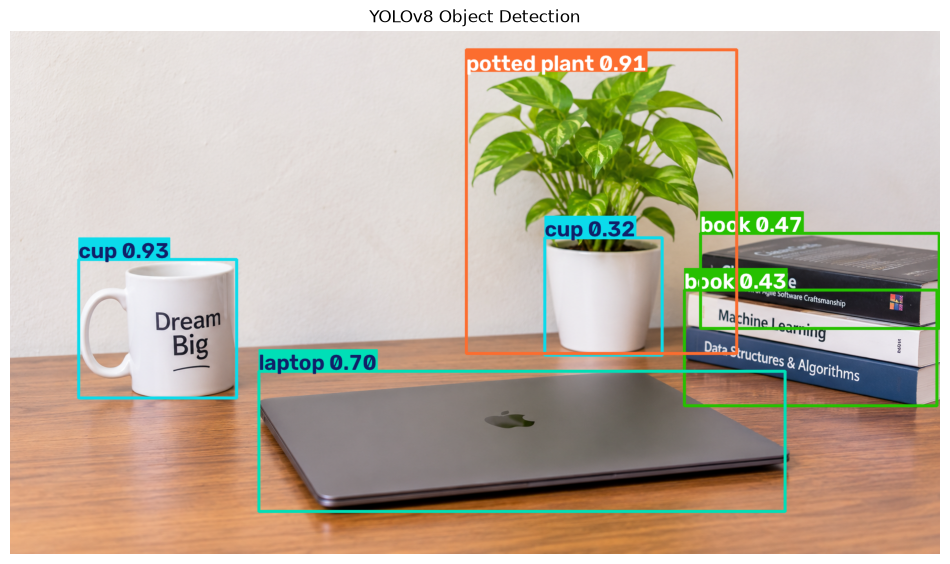

In [25]:
result = results[0]

detected_image = result.plot()

detected_image_rgb = cv2.cvtColor(
    detected_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))

plt.imshow(detected_image_rgb)

plt.title("YOLOv8 Object Detection")
plt.axis("off")

plt.show()